# Part 1: thresholds derived from vulnerable code

Thresholds for each metric and language, derived from the **vulnerable** snippets (`original_code`) of the combined
security dataset (`codedee_combined_pairs.jsonl`, branch `security_analysis`), then the spread of every metric.

**Data.** 1384 pairs, minus exact duplicate snippets (same key as `split_dataset_kb.py`) = 1279.
Measured by `measure_snippets.py` with the same `metrics.py` as the web-app benchmark. Label comments such as
`// VULNERABLE: no authz` are removed first. Snippets the repo pipeline would skip (generated, minified, vendored,
> 1 MB) and snippets that do not parse (tree-sitter reports an error) are counted, not measured.

**Left out:** Gift's CVEfixes rows (`CVEFIXES_CVE_YYYY_N_NNNNN`, 769 pairs) are a fix commit's removed / added
diff lines glued together, often across files, and GHSA rows (70 pairs) are truncated line windows of a file joined
together; neither is one real piece of code. **Used:** AppSecBench, SecureCodePairs and Gift's hand-written rows
(`SEC_*`, `SYN_*`, `SEMGREP_*`, `CYBERSECEVAL_*`, `OWASP_*`, ...).

**Method.** Snippets have no repository, so there is no per-system normalisation: every language is one pooled set.
- Alves et al. (2010), 70/80/90, entity weight = SLOC (cognitive: `cognitive_sloc`), with `derive.py`'s own
  `distribution()` / `threshold()`: cyclomatic, cognitive, params, function SLOC (per function); file SLOC (per
  *file-sized* snippet = has an import or more than one top-level function); duplicated blocks (per snippet).
- Vale et al. (2019), 3/15/90/95, every snippet weighs the same: comment density.
- `ce` / `ca` are not possible: a snippet has no import graph.

In [1]:
import sys
from collections import Counter
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()  # this notebook's folder: 05_derive_threshold/security
sys.path.insert(0, str(HERE.parent / "scripts"))
RESULTS, FIGURES = HERE / "results", HERE / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

if not (RESULTS / "snippets.csv").exists():  # measure once (about 40 s); delete the CSVs to re-measure
    import measure_snippets
    measure_snippets.main()
snippets = pd.read_csv(RESULTS / "snippets.csv")
functions = pd.read_csv(RESULTS / "functions.csv")
LANGS = ["python", "javascript", "typescript"]

# Chart style (light surface, reference data-viz palette; colors validated for color-blind separation)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LANG_COLOR = {"python": "#2a78d6", "javascript": "#eb6834", "typescript": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "legend.frameon": False,
})

## Data used

Per language and source: how many vulnerable snippets were measured, and how many hold at least one function or
look like a whole file.

In [2]:
vs = snippets[snippets.version == "vulnerable"]
vf = functions[functions.version == "vulnerable"]
m = vs[vs.status == "measured"].copy()
m["file_sized"] = m.file_sized.fillna(False).astype(bool)

overview = vs.groupby(["language", "source"]).agg(
    snippets=("sample_id", "size"),
    measured=("status", lambda s: (s == "measured").sum()),
    parse_error=("status", lambda s: (s == "parse_error").sum()),
    excluded=("status", lambda s: s.isin(["generated_vendored", "vendored_library"]).sum()),
).join(m.groupby(["language", "source"]).agg(
    with_functions=("functions", lambda x: (x > 0).sum()), file_sized=("file_sized", "sum"),
)).fillna(0).astype(int)
display(overview)
display(overview.groupby(level="language").sum().loc[LANGS].assign(
    functions=vf.groupby("language").size()))

snippets  measured  parse_error  excluded  \
language   source                                                       
javascript appsecbench            77        77            0         0   
           gift                   25        25            0         0   
           securecodepairs        26        24            2         0   
python     appsecbench            82        82            0         0   
           gift                   50        50            0         0   
           securecodepairs        66        65            1         0   
typescript appsecbench            81        81            0         0   
           gift                   18        18            0         0   
           securecodepairs        15        15            0         0   

                            with_functions  file_sized  
language   source                                       
javascript appsecbench                  75           4  
           gift                         25          17  
           securecodepairs              18           3  
python     appsecbench                  82           7  
           gift                         49          25  
           securecodepairs              49          14  
typescript appsecbench                  79           7  
           gift                         18          17  
           securecodepairs              10           4

,snippets,measured,parse_error,excluded,with_functions,file_sized,functions
language,,,,,,,
python,198,197,1,0,180,46,181
javascript,128,126,2,0,118,24,142
typescript,114,114,0,0,107,28,130


## Thresholds

Derived from the vulnerable snippets. `entities` = functions or snippets behind the threshold.

In [3]:
from derive import distribution, fmt, threshold  # same quantile code as the web-app thresholds

ALVES_Q, VALE_Q = (70, 80, 90), (3, 15, 90, 95)


def weighted(values, weights):
    h = Counter()
    for v, w in zip(values, weights):
        h[v if isinstance(v, Fraction) else int(v)] += int(w)
    return h


def metric_sets(lang):
    """metric -> (Counter value -> weight, quantiles, method, entities); weights as in derive.py."""
    f = vf[vf.language == lang]
    cog = f[f.cognitive.notna()]
    s = m[(m.language == lang) & (m.sloc > 0)]
    fs = s[s.file_sized]
    return {
        "cyclomatic": (weighted(f.cyclomatic, f.sloc), ALVES_Q, "alves", len(f)),
        "cognitive": (weighted(cog.cognitive, cog.cognitive_sloc), ALVES_Q, "alves", len(cog)),
        "params": (weighted(f.params, f.sloc), ALVES_Q, "alves", len(f)),
        "function_sloc": (weighted(f.sloc, f.sloc), ALVES_Q, "alves", len(f)),
        "file_sloc": (weighted(fs.sloc, fs.sloc), ALVES_Q, "alves", len(fs)),
        "duplicated_blocks": (weighted(s.duplicated_blocks, s.sloc), ALVES_Q, "alves", len(s)),
        "comment_density": (weighted([Fraction(100 * int(c), int(n) + int(c)) for c, n in zip(s.cloc, s.sloc)],
                                     [1] * len(s)), VALE_Q, "vale", len(s)),
    }


rows = []
for lang in LANGS:
    for metric, (hist, qs, method, n) in metric_sets(lang).items():
        dist = distribution([lang], {lang: {metric: hist}}, metric, per_system=False)
        rows += [{"language": lang, "metric": metric, "method": method, "quantile": q,
                  "threshold": fmt(threshold(dist, q)), "entities": n} for q in qs]
thr = pd.DataFrame(rows)
thr.to_csv(RESULTS / "thresholds.csv", index=False, lineterminator="\n")

thr.groupby(["metric", "language"], sort=False).agg(
    method=("method", "first"),
    quantiles=("quantile", lambda q: " / ".join(map(str, q))),
    thresholds=("threshold", " / ".join),
    entities=("entities", "first"))

,,method,quantiles,thresholds,entities
metric,language,,,,
cyclomatic,python,alves,70 / 80 / 90,1 / 1 / 2,181
cognitive,python,alves,70 / 80 / 90,0 / 1 / 1,181
params,python,alves,70 / 80 / 90,1 / 1 / 2,181
function_sloc,python,alves,70 / 80 / 90,5 / 8 / 11,181
file_sloc,python,alves,70 / 80 / 90,14 / 17 / 20,46
duplicated_blocks,python,alves,70 / 80 / 90,0 / 0 / 0,197
comment_density,python,vale,3 / 15 / 90 / 95,0.00 / 0.00 / 33.33 / 40.00,197
cyclomatic,javascript,alves,70 / 80 / 90,1 / 1 / 2,142
cognitive,javascript,alves,70 / 80 / 90,0 / 0 / 1,142


## Spread of each metric per language

Share of functions (function metrics) or snippets (file metrics) in each value range, per language; unweighted,
each language's bars add up to 100 %.

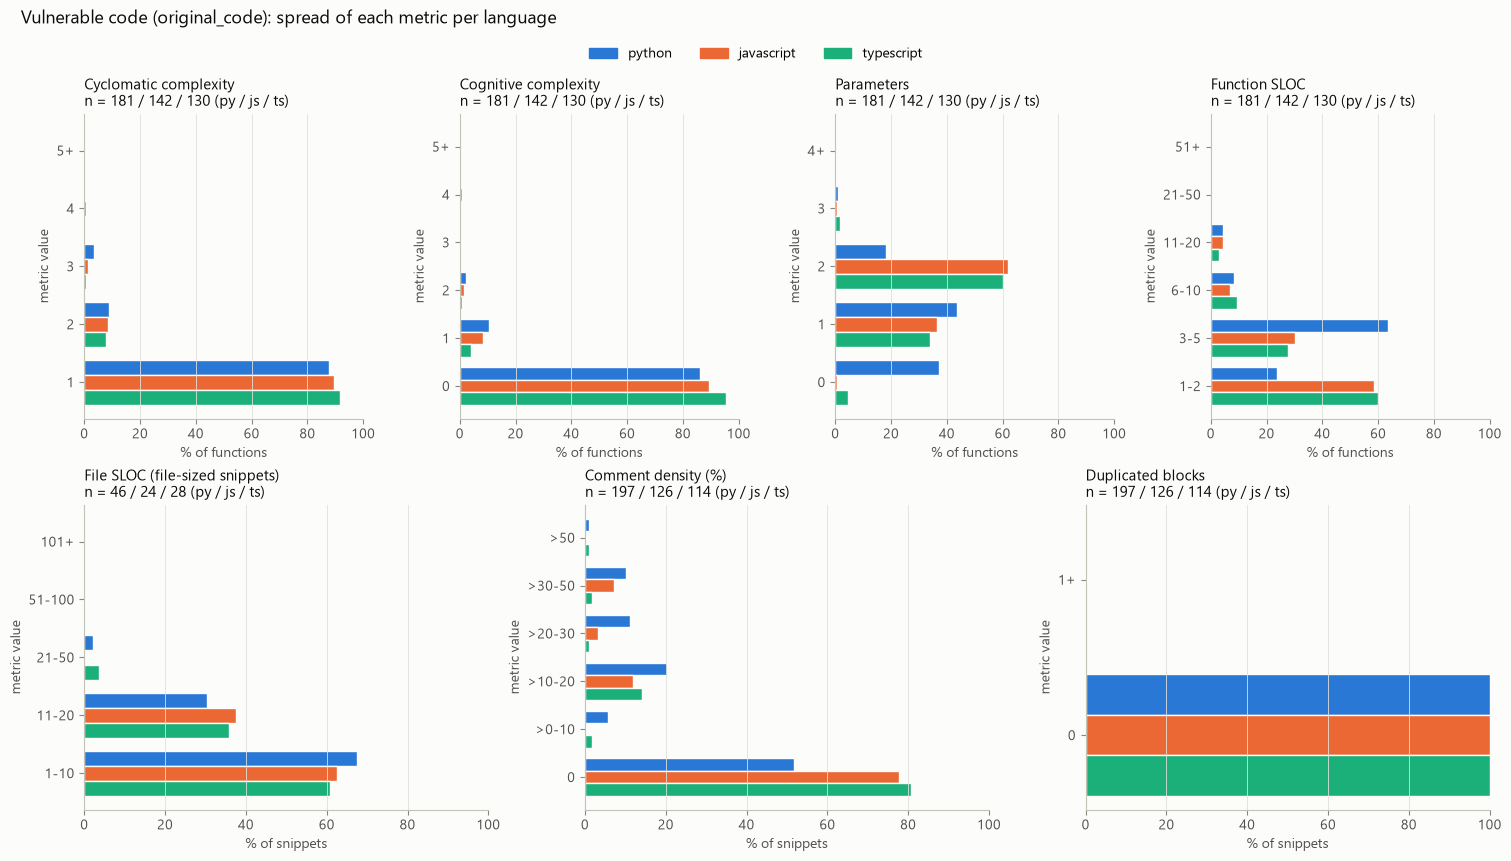

In [4]:
def seven_panels():
    """4 function-metric panels on top, 3 file-metric panels stretched across the bottom row."""
    fig = plt.figure(figsize=(15, 8.5), layout="constrained")
    gs = fig.add_gridspec(2, 12)
    return fig, ([fig.add_subplot(gs[0, 3 * i:3 * i + 3]) for i in range(4)]
                 + [fig.add_subplot(gs[1, 4 * i:4 * i + 4]) for i in range(3)])


def finish(fig, axes, title):
    """Title in the top band, language legend centred under it."""
    fig.get_layout_engine().set(rect=(0, 0, 1, 0.92))
    from matplotlib.patches import Patch
    fig.legend([Patch(color=LANG_COLOR[lang]) for lang in LANGS], LANGS, loc="upper center",
               bbox_to_anchor=(0.5, 0.965), ncols=3)
    fig.text(0.01, 0.995, title, ha="left", va="top", fontsize=13, color=INK)


INF = float("inf")
f_by = {lang: vf[vf.language == lang] for lang in LANGS}
s_by = {lang: m[(m.language == lang) & (m.sloc > 0)] for lang in LANGS}
VALUES = {  # metric -> (title, values per language)
    "cyclomatic": ("Cyclomatic complexity", lambda l: f_by[l].cyclomatic),
    "cognitive": ("Cognitive complexity", lambda l: f_by[l].cognitive.dropna()),
    "params": ("Parameters", lambda l: f_by[l].params),
    "function_sloc": ("Function SLOC", lambda l: f_by[l].sloc),
    "file_sloc": ("File SLOC (file-sized snippets)", lambda l: s_by[l][s_by[l].file_sized].sloc),
    "comment_density": ("Comment density (%)", lambda l: 100 * s_by[l].cloc / (s_by[l].sloc + s_by[l].cloc)),
    "duplicated_blocks": ("Duplicated blocks", lambda l: s_by[l].duplicated_blocks),
}
BINS = {  # metric -> (right-closed bin edges, labels)
    "cyclomatic": ([0, 1, 2, 3, 4, INF], ["1", "2", "3", "4", "5+"]),
    "cognitive": ([-1, 0, 1, 2, 3, 4, INF], ["0", "1", "2", "3", "4", "5+"]),
    "params": ([-1, 0, 1, 2, 3, INF], ["0", "1", "2", "3", "4+"]),
    "function_sloc": ([0, 2, 5, 10, 20, 50, INF], ["1-2", "3-5", "6-10", "11-20", "21-50", "51+"]),
    "file_sloc": ([0, 10, 20, 50, 100, INF], ["1-10", "11-20", "21-50", "51-100", "101+"]),
    "comment_density": ([-1, 0, 10, 20, 30, 50, 100], ["0", ">0-10", ">10-20", ">20-30", ">30-50", ">50"]),
    "duplicated_blocks": ([-1, 0, INF], ["0", "1+"]),
}
FILE_METRICS = {"file_sloc", "comment_density", "duplicated_blocks"}
BAR = 0.26

fig, axes = seven_panels()
for ax, (metric, (title, values)) in zip(axes, VALUES.items()):
    edges, labels = BINS[metric]
    y = range(len(labels))  # lowest value at the bottom
    counts = []
    for i, lang in enumerate(LANGS):
        v = values(lang).astype(float)
        counts.append(len(v))
        pct = pd.cut(v, edges, labels=labels).value_counts(normalize=True).reindex(labels).fillna(0) * 100
        ax.barh([p - (i - 1) * BAR for p in y], pct, BAR, color=LANG_COLOR[lang], edgecolor=SURFACE,
                linewidth=1, label=lang)  # python on top within each group
    ax.set_yticks(list(y), labels)
    ax.set_xlim(0, 100)
    ax.grid(False)
    ax.grid(axis="x")
    ax.set_ylabel("metric value")
    ax.set_xlabel("% of snippets" if metric in FILE_METRICS else "% of functions")
    ax.set_title(f"{title}\nn = {' / '.join(map(str, counts))} (py / js / ts)", loc="left")
finish(fig, axes, "Vulnerable code (original_code): spread of each metric per language")
fig.savefig(FIGURES / "part1_spread.png", dpi=150)
plt.show()

## Derived thresholds per language

The thresholds from the table above as bars: t70 / t80 / t90 per language (comment density: Vale's t3 / t15 / t90 /
t95). Bar height = threshold value; the number is printed on each bar.

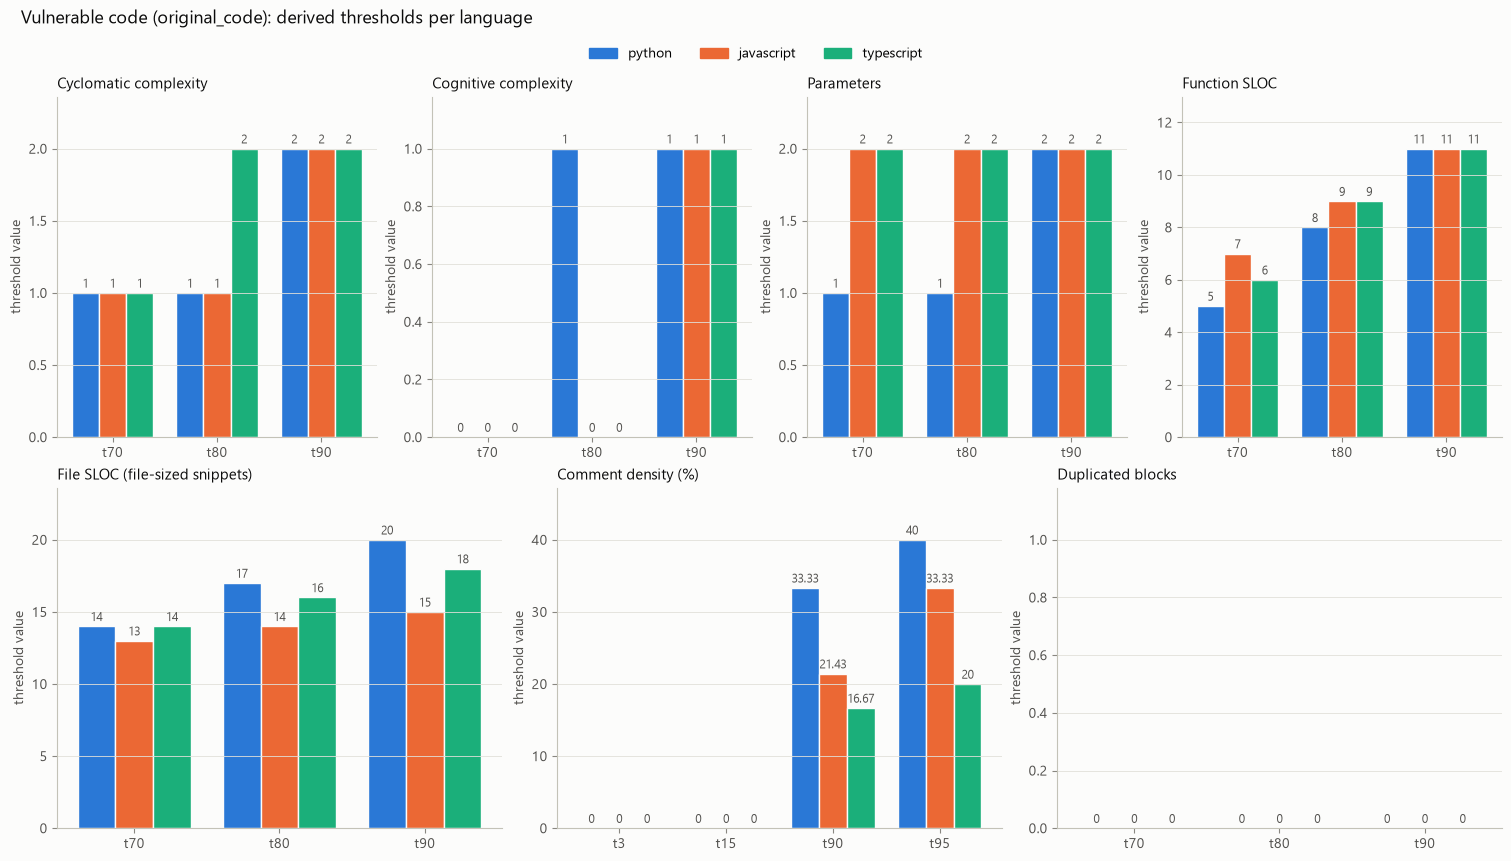

In [5]:
fig, axes = seven_panels()
for ax, (metric, (title, _)) in zip(axes, VALUES.items()):
    rows = thr[thr.metric == metric]
    quantiles = sorted(rows["quantile"].unique())
    x = range(len(quantiles))
    for i, lang in enumerate(LANGS):
        t = rows[rows.language == lang].set_index("quantile").threshold.reindex(quantiles)
        bars = ax.bar([p + (i - 1) * BAR for p in x], t.astype(float), BAR, color=LANG_COLOR[lang],
                      edgecolor=SURFACE, linewidth=1, label=lang)
        ax.bar_label(bars, labels=[s.removesuffix(".00") for s in t], padding=2, fontsize=8.5, color=INK2)
    ax.set_xticks(list(x), [f"t{q}" for q in quantiles])
    ax.set_ylim(0, max(1, rows.threshold.astype(float).max()) * 1.18)
    ax.set_ylabel("threshold value")
    ax.set_title(title, loc="left")
finish(fig, axes, "Vulnerable code (original_code): derived thresholds per language")
fig.savefig(FIGURES / "part1_thresholds.png", dpi=150)
plt.show()